# Reconstruction algorithms on measured data

The [algorithms tutorial](t_algorithms.ipynb) shows how to run OSEM, OSMAPOSL, BSREM and KEM, and the [accuracy tutorial](t_accuracy_known_truth.ipynb) measures them against the true activity of a simulation. A measured scan has no true image, but a phantom of known shape still says a lot: how much of each sphere's contrast an algorithm recovers, how noisy it leaves the uniform background, how well its image explains the measured projections, and how all three change with every iteration. This tutorial measures them on a Siemens Symbia scan of a NEMA image quality phantom filled with Lu-177, a body-shaped tank of water with six hot spheres, and compares the algorithms at the same noise rather than after an arbitrary number of iterations.

You will:

- load the spheres and the background as regions that come with the data,
- record region statistics and the data fit after every iteration with a callback,
- compare OSEM, with and without a post-filter, OSMAPOSL, BSREM and KEM with contrast-noise curves, against the scanner's own reconstruction.

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("SPECT/Lu177-NEMA-SymT2")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("SPECT/Lu177-NEMA-SymT2")

SPECT/Lu177-NEMA-SymT2: already downloaded


In [2]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
import pytomography
from pytomography import io
from pytomography.transforms.SPECT import SPECTAttenuationTransform, SPECTPSFTransform
from pytomography.transforms.shared import GaussianFilter, KEMTransform
from pytomography.projectors.SPECT import SPECTSystemMatrix
from pytomography.projectors.shared import KEMSystemMatrix
from pytomography.likelihoods import PoissonLogLikelihood
from pytomography.algorithms import OSEM, OSMAPOSL, BSREM, KEM
from pytomography.priors import RelativeDifferencePrior, TopNAnatomyNeighbourWeight
from pytomography.callbacks import Callback

In [3]:
# Memory: this tutorial peaks at about 7.5 GB of RAM, during KEM, whose kernel (1 GB) is built on the CPU, a chunk of
# voxels at a time, and then kept on the GPU, which on Windows counts as RAM too. Each reconstruction prints its
# estimate before it runs (estimate_memory): about 4.4 GB for OSEM, most of it PyTorch and CUDA themselves, and 6 GB for
# KEM. RAM_GB changes nothing here: SPECT reconstructions this size never need to split their work. kernel_on_gpu=False
# keeps KEM's kernel in RAM instead of GPU memory, three times slower.
RAM_GB = 25
pytomography.set_memory_budget(RAM_GB)

## 1. The scan and the system matrix

The setup of the [DICOM introduction](t_dicomdata.ipynb): the 208 keV photopeak of Lu-177, 96 views of 15 s, with a triple-energy-window scatter estimate, attenuation from the CT, and the collimator-detector response of the medium-energy collimator. The scanner's own reconstruction, 3D OSEM with 4 iterations of 8 subsets, comes with the data. `read_dicom` puts the grid in the frame of the scan's CT, with the registration of the SPECT to the CT that Siemens records in the projection file (4 mm and half a degree here), and the attenuation map and the scanner's reconstruction are put on it by their own places in the patient.

In [4]:
path = DATA / 'SPECT' / 'Lu177-NEMA-SymT2'
file_NM = str(path / 'projection_data.dcm')
files_CT = sorted(str(f) for f in (path / 'CT').glob('*'))
projections, object_meta, proj_meta = io.SPECT.read_dicom(file_NM)
photopeak = projections[0]  # the 208 keV window
scatter = io.SPECT.energy_window_scatter(projections, proj_meta, peak=0, lower=1, upper=2)
photon_keV = proj_meta.energy_windows[0].photon_keV
attenuation_map = io.attenuation_map(files_CT, object_meta, energy_keV=photon_keV)  # 1/mm
att_transform = SPECTAttenuationTransform(attenuation_map)
psf_transform = SPECTPSFTransform(io.SPECT.collimator_psf('SY-ME', photon_keV, intrinsic_fwhm_mm=3.8))
system_matrix = SPECTSystemMatrix(obj2obj_transforms=[att_transform, psf_transform], proj2proj_transforms=[],
                                  object_meta=object_meta, proj_meta=proj_meta)
likelihood = PoissonLogLikelihood(system_matrix, photopeak, scatter)

# the scanner's reconstruction, put on our grid by its own place in the patient
scanner = io.load_image(path / 'scanner_recon.dcm')
recon_scanner = scanner.on(object_meta) / proj_meta.num_projections
print(f"{photopeak.sum():.3g} counts in the photopeak; the scanner's reconstruction: {scanner.meta['ConvolutionKernel'][0]}")

5.78e+06 counts in the photopeak; the scanner's reconstruction: 3DOSEM,4i,8s


## 2. Where the spheres are

The phantom follows the NEMA NU 2 and IEC 61675-1 standards: six spheres of 10, 13, 17, 22, 28 and 37 mm inside diameter, their centres in one transverse plane on a circle of 57.2 mm radius around the axis of the lung insert, a cylinder of low-density foam down the middle. The regions come with the data as a segmentation, `lu177_nema_symt2_rois.seg.nrrd`, in the patient's frame on a grid of 0.8 mm voxels: each sphere, the lung insert and the background. `io.load_mask` reads it, and `.on(object_meta, label=...)` gives the fraction of each voxel of our grid that a region fills. A voxel belongs to a region when the region fills more than half of it.

The sphere walls are too thin to see in the CT, so `docs/tools/make_roi_masks.py` in the PyTomography repository placed the spheres from the SPECT. It found the position of the ring that puts the most counts of the scanner's own reconstruction inside the six spheres, starting from the lung insert's axis in the CT. Each sphere hangs from its own stem, which can leave it a few millimetres off the ideal ring, so each was then moved on its own, by at most 10 mm, to the place that holds the most counts. The 10 mm sphere cannot be seen in any reconstruction of this scan, so it stays where the ring puts it. The 13 mm sphere is the least certain: fits on different reconstructions place it up to 5 mm apart, about one voxel. The fits used the scanner's reconstruction, so the regions favour none of the algorithms compared below.

The background is the phantom's water at least 15 mm from anything else in the CT (the walls, the lid and base, the lung insert, the spheres' stems), and at least 20 mm from every sphere, where the spheres' counts spread by the camera's resolution no longer reach.

In [5]:
rois = io.load_mask(path / 'lu177_nema_symt2_rois.seg.nrrd')  # made once by docs/tools/make_roi_masks.py
diameters = [37, 28, 22, 17, 13, 10]  # mm
spheres = {f'{d} mm': rois.on(object_meta, label=f'sphere_{d}mm') > 0.5 for d in diameters}
background = rois.on(object_meta, label='background') > 0.5
dx = object_meta.dr[0]  # voxel size, mm
for name, mask in spheres.items():
    print(f"sphere {name:6s} {int(mask.sum()):4d} voxels")
print(f"background   {int(background.sum())} voxels ({background.sum() * dx ** 3 / 1000:.0f} mL)")

sphere 37 mm   235 voxels
sphere 28 mm   103 voxels
sphere 22 mm    46 voxels
sphere 17 mm    21 voxels
sphere 13 mm    10 voxels
sphere 10 mm     4 voxels
background   47232 voxels (5208 mL)


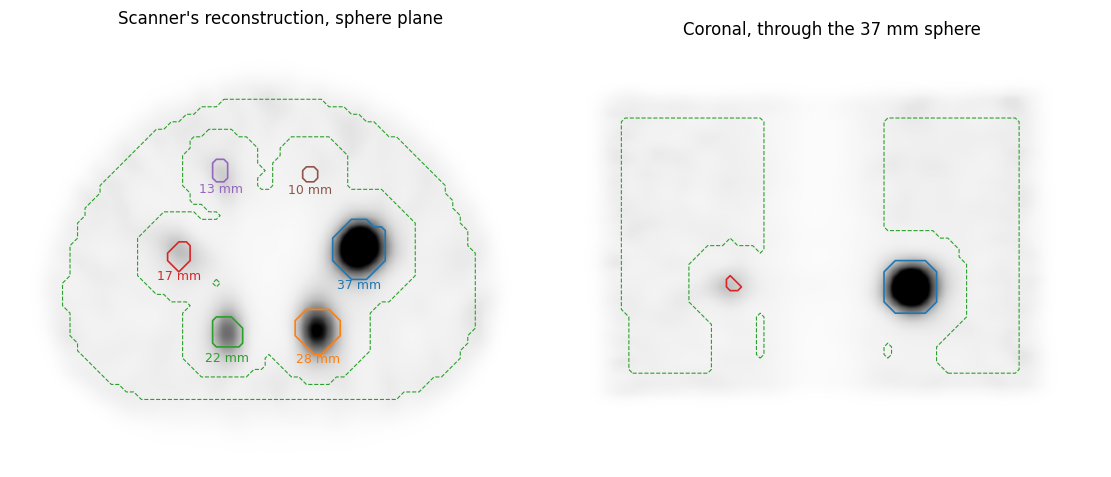

In [6]:
image = recon_scanner.cpu().numpy()
_, y, z = torch.nonzero(spheres['37 mm']).float().mean(0).round().int().tolist()  # through the 37 mm sphere's centre
crop = (slice(30, 102), slice(40, 98), slice(39, 94))  # x, y, z around the phantom
colors = plt.cm.tab10(np.arange(len(spheres)))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), constrained_layout=True)
for ax, cut, title, origin in [(axes[0], lambda a: a[crop[0], crop[1], z], "Scanner's reconstruction, sphere plane", 'upper'),
                               (axes[1], lambda a: a[crop[0], y, crop[2]], 'Coronal, through the 37 mm sphere', 'lower')]:
    # anterior up in the axial view, head up in the coronal one
    ax.imshow(cut(image).T, cmap='Greys', vmax=0.5 * image.max(), origin=origin, interpolation='gaussian')
    for mask, color in zip(spheres.values(), colors):
        if cut(mask).any():
            ax.contour(cut(mask).cpu().T, [0.5], colors=[color], linewidths=1.2)
    ax.contour(cut(background).cpu().T, [0.5], colors='tab:green', linewidths=0.8, linestyles='--')
    ax.set_title(title)
    ax.axis('off')
for (name, mask), d, color in zip(spheres.items(), diameters, colors):
    cx, cy, _ = torch.nonzero(mask).float().mean(0).tolist()
    axes[0].text(cx - crop[0].start, cy - crop[1].start + d / 2 / dx + 1.5, name, color=color, ha='center', fontsize=9)
plt.show()

## 3. A callback that measures every iteration

A callback runs after every subset and returns the image, which the algorithm keeps. This one, at the end of each iteration:

- the **contrast** of each sphere: its mean over the background's mean. The filling ratio of the phantom is not recorded with the scan, so this tutorial compares the contrasts the algorithms reach with each other, not with a true value; for a sphere of true ratio $R$, the recovery coefficient is $(\text{contrast} - 1)/(R - 1)$.
- the **noise**: the standard deviation of the background's voxels over their mean.
- the **data fit**: the Poisson log-likelihood of all the projections, $\sum_i g_i \ln \bar g_i - \bar g_i$ with $\bar g = Hf + s$; computing it takes one more forward projection per iteration.
- the **change** of the image since the previous iteration, $\lVert f^{n} - f^{n-1} \rVert / \lVert f^n \rVert$.

`post_filter` measures the image after a filter as well, without changing the image the algorithm continues from.

In [7]:
def contrast_and_noise(image):
    b = image[background]
    return [float(image[mask].mean() / b.mean()) for mask in spheres.values()], float(b.std() / b.mean())

def log_likelihood(image):
    expected = system_matrix.forward(image) + scatter
    return float((torch.xlogy(photopeak, expected) - expected).sum())

class PhantomStatistics(Callback):
    def __init__(self, n_subsets, post_filter=None):
        self.n_subsets, self.post_filter, self.previous = n_subsets, post_filter, None
        self.contrast, self.noise, self.log_likelihood, self.change = [], [], [], []
        self.contrast_filtered, self.noise_filtered = [], []
    def run(self, object, n_iter, n_subset):
        if n_subset == self.n_subsets - 1:  # the last subset: the end of an iteration
            contrast, noise = contrast_and_noise(object)
            self.contrast.append(contrast)
            self.noise.append(noise)
            self.log_likelihood.append(log_likelihood(object))
            if self.previous is not None:
                self.change.append(float((object - self.previous).norm() / object.norm()))
            self.previous = object.clone()
            if self.post_filter is not None:
                contrast, noise = contrast_and_noise(self.post_filter(object))
                self.contrast_filtered.append(contrast)
                self.noise_filtered.append(noise)
        return object

## 4. Reconstruct

Every algorithm runs for 40 iterations of 8 subsets, as in the [algorithms tutorial](t_algorithms.ipynb):

- **OSEM**, measured as it is and after a Gaussian post-filter of 10 mm FWHM, the usual clinical practice.
- **OSMAPOSL** and **BSREM** with a relative difference prior (`gamma=2`), which penalises differences between neighbouring voxels relative to their values. OSMAPOSL has the settings of the algorithms tutorial: `beta` 0.3, and for each voxel only the 8 neighbours most like it in the attenuation map. BSREM uses all 26 neighbours, a prior that does not need the CT, and runs for four values of `beta`, the strength of the prior.
- **KEM**, with the settings of the algorithms tutorial: its image is a kernel, built from the attenuation map, applied to the coefficients it iterates.

In [8]:
n_iters, n_subsets = 40, 8
results, times = {}, {}
post_filter = GaussianFilter(10)  # FWHM in mm
post_filter.configure(object_meta, proj_meta)

print(OSEM(likelihood).estimate_memory(n_subsets=n_subsets))
t0 = time.time()
results['OSEM'] = PhantomStatistics(n_subsets, post_filter)
recon_osem = OSEM(likelihood)(n_iters=n_iters, n_subsets=n_subsets, callback=results['OSEM'])
times['OSEM'] = time.time() - t0
recon_osem_filtered = post_filter(recon_osem)

OSEM (SPECTSystemMatrix): 8 subsets, memory budget 25 GB
Peak ~ 4.4 GB RAM, 1.2 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 0.00 GB RAM, 0.2 GB GPU (image 0.01 GPU, H_m^T 1 of 8 subsets 0.1 GPU, images of an update 0.03 GPU, rotation grids of every view (cached) 0.1 GPU, what the object transforms keep 0.01 GPU, projections (the data) 0.01 GPU, additive term 0.01 GPU)
  one subset at a time: 0.00 GB RAM, 0.1 GB GPU (projections of a subset: measured, expected, additive term, of ones, padded copy 0.01 GPU, padded object, support and sum of a projection 0.1 GPU)
  projector chunks: 0.00 GB RAM, 0.1 GB GPU (one view: rotated object and the transforms' temporaries 0.1 GPU)
  Python, CUDA, allocator: 3.2 GB RAM, 0.8 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 0.2 GPU, memory the allocators keep (Windows) 0.1 RAM)
To use less: 4 subsets ~ 4.3 GB RAM, 1.

In [9]:
t0 = time.time()
results['OSMAPOSL'] = PhantomStatistics(n_subsets)
prior = RelativeDifferencePrior(beta=0.3, gamma=2, weight=TopNAnatomyNeighbourWeight(attenuation_map, N_neighbours=8))
recon_osmaposl = OSMAPOSL(likelihood, prior=prior)(n_iters=n_iters, n_subsets=n_subsets, callback=results['OSMAPOSL'])
times['OSMAPOSL'] = time.time() - t0

betas = [0.01, 0.03, 0.1, 0.3]
recon_bsrem = {}
for beta in betas:
    t0 = time.time()
    results[f'BSREM {beta}'] = PhantomStatistics(n_subsets)
    bsrem = BSREM(likelihood, prior=RelativeDifferencePrior(beta=beta, gamma=2), relaxation_sequence=lambda n: 1 / (n / 50 + 1))
    recon_bsrem[beta] = bsrem(n_iters=n_iters, n_subsets=n_subsets, callback=results[f'BSREM {beta}'])
    times[f'BSREM {beta}'] = time.time() - t0

t0 = time.time()
kem_transform = KEMTransform(support_objects=[attenuation_map], support_kernels_params=[[0.0005]],  # 1/mm
                             distance_kernel_params=[4], top_N=40, kernel_on_gpu=True)  # mm
likelihood_kem = PoissonLogLikelihood(KEMSystemMatrix(system_matrix, kem_transform), photopeak, scatter)
results['KEM'] = PhantomStatistics(n_subsets)
kem = KEM(likelihood_kem)
print(kem.estimate_memory(n_subsets=n_subsets))
recon_kem = kem(n_iters=n_iters, n_subsets=n_subsets, callback=results['KEM'])
times['KEM'] = time.time() - t0
for name, t in times.items():
    print(f"{name:12s} {t:5.1f} s")

KEM (KEMSystemMatrix): 8 subsets, memory budget 25 GB
Peak ~ 6.2 GB RAM, 2.7 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 0.00 GB RAM, 1.3 GB GPU (image 0.01 GPU, H_m^T 1 of 8 subsets 0.1 GPU, images of an update 0.03 GPU, rotation grids of every view (cached) 0.1 GPU, what the object transforms keep 0.01 GPU, KEM kernel 1.0 GPU, KEM support images 0.01 GPU, projections (the data) 0.01 GPU, additive term 0.01 GPU)
  one subset at a time: 0.00 GB RAM, 0.1 GB GPU (projections of a subset: measured, expected, additive term, of ones, padded copy 0.01 GPU, padded object, support and sum of a projection 0.1 GPU)
  projector chunks: 0.00 GB RAM, 0.2 GB GPU (one view: rotated object and the transforms' temporaries 0.1 GPU, applying the KEM kernel: result, neighbour, kernel slice, product 0.03 GPU)
  Python, CUDA, allocator: 3.6 GB RAM, 1.2 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cach

OSEM           7.5 s
OSMAPOSL      17.0 s
BSREM 0.01    11.9 s
BSREM 0.03    12.1 s
BSREM 0.1     12.1 s
BSREM 0.3     12.0 s
KEM           26.9 s


## 5. Convergence

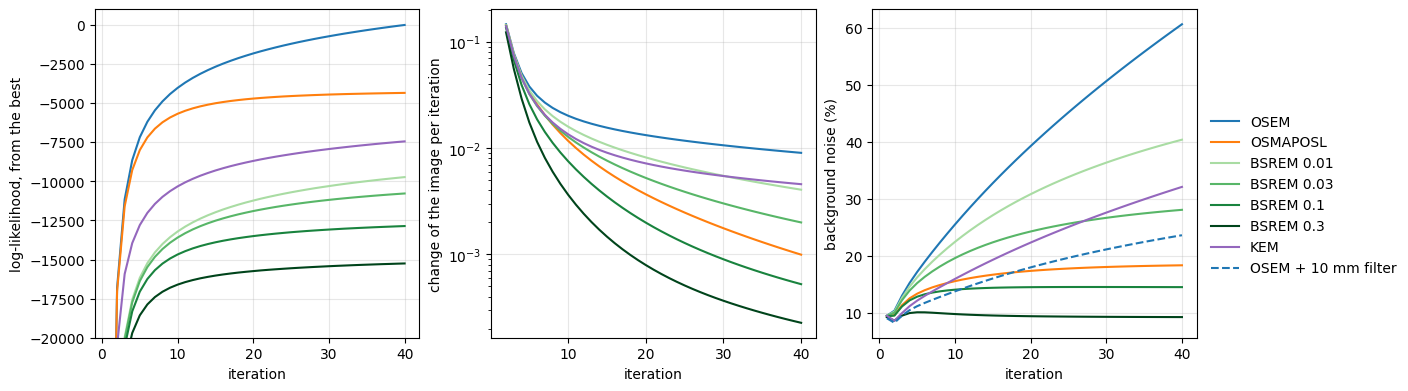

In [10]:
scanner_contrast, scanner_noise = contrast_and_noise(recon_scanner)
color = {'OSEM': 'tab:blue', 'OSMAPOSL': 'tab:orange', 'KEM': 'tab:purple'}
color.update({f'BSREM {b}': plt.cm.Greens(0.35 + 0.65 * i / max(1, len(betas) - 1)) for i, b in enumerate(betas)})
iterations = np.arange(1, n_iters + 1)
reference = max(r.log_likelihood[-1] for r in results.values())
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), constrained_layout=True)
for name, r in results.items():
    axes[0].plot(iterations, np.array(r.log_likelihood) - reference, color=color[name], label=name)
    axes[1].semilogy(iterations[1:], r.change, color=color[name])
    axes[2].plot(iterations, 100 * np.array(r.noise), color=color[name])
axes[2].plot(iterations, 100 * np.array(results['OSEM'].noise_filtered), color='tab:blue', ls='--', label='OSEM + 10 mm filter')
axes[0].set(ylabel='log-likelihood, from the best', ylim=(-2e4, 1e3))
axes[1].set(ylabel='change of the image per iteration')
axes[2].set(ylabel='background noise (%)')
for ax in axes:
    ax.set_xlabel('iteration')
    ax.grid(alpha=0.3)
handles = axes[0].get_lines() + axes[2].get_lines()[-1:]
fig.legend(handles, [h.get_label() for h in handles], loc='outside right center', frameon=False)
plt.show()

OSEM fits the data best, and its fit is still improving after 40 iterations, but its noise grows with every iteration: at the end the background varies by 61% from voxel to voxel, and the image still changes by almost 1% per iteration. With subsets OSEM never settles on one image, so where it stops sets the noise. The priors give up some of the fit for smoothness: the log-likelihoods of OSMAPOSL and BSREM level off below OSEM's, lower the larger `beta`, and so does their noise. BSREM's relaxation makes its steps shrink, so its image converges to one that `beta` sets rather than the number of iterations: with `beta` 0.3 it changes by 0.02% per iteration at the end. KEM's kernel can only make images that are smooth within regions of similar attenuation, which also costs it fit; its noise still grows, more slowly than OSEM's.

## 6. Contrast against noise

Each curve follows one algorithm through its iterations, from the open circle; BSREM's curve joins its four values of `beta` after the last iteration, the weakest prior on the right. The star is the scanner's reconstruction. Higher at the same noise is better: every algorithm sees the same projections, the same regions and the same phantom, so a curve above another recovers more contrast for the same noise, whatever the true filling ratio is, as long as the contrast stays below it. The 10 mm sphere is left out: it cannot be seen in any of these images.

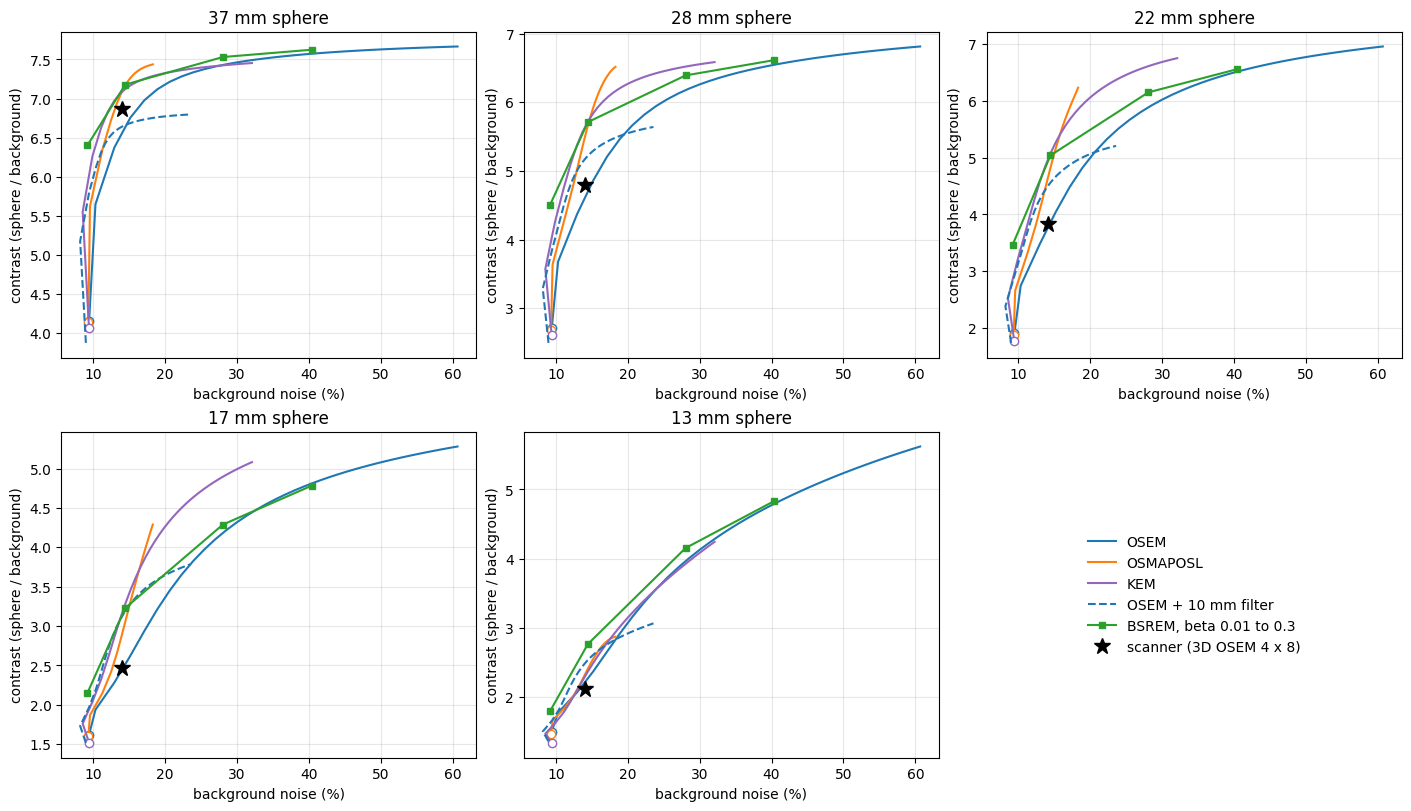

In [11]:
def curve(ax, noise, contrast, i, **style):
    ax.plot(100 * np.array(noise), np.array(contrast)[:, i], **style)

fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
for i, (ax, name) in enumerate(zip(axes.flat, list(spheres)[:5])):  # the 10 mm sphere is not visible: left out
    for algorithm in ['OSEM', 'OSMAPOSL', 'KEM']:
        r = results[algorithm]
        curve(ax, r.noise, r.contrast, i, color=color[algorithm], label=algorithm)
        ax.plot(100 * r.noise[0], r.contrast[0][i], 'o', mfc='white', color=color[algorithm])
    r = results['OSEM']
    curve(ax, r.noise_filtered, r.contrast_filtered, i, color='tab:blue', ls='--', label='OSEM + 10 mm filter')
    final = [results[f'BSREM {b}'] for b in betas]
    curve(ax, [r.noise[-1] for r in final], [r.contrast[-1] for r in final], i, color='tab:green', marker='s', ms=4,
          label=f"BSREM, beta {betas[0]} to {betas[-1]}")
    ax.plot(100 * scanner_noise, scanner_contrast[i], '*', color='k', ms=12, label="scanner (3D OSEM 4 x 8)")
    ax.set_title(f'{name} sphere')
    ax.set(xlabel='background noise (%)', ylabel='contrast (sphere / background)')
    ax.grid(alpha=0.3)
axes[1, 2].legend(*axes[0, 0].get_legend_handles_labels(), loc='center', frameon=False)
axes[1, 2].axis('off')
plt.show()

In [12]:
final = {name: (r.contrast[-1], r.noise[-1]) for name, r in results.items()}
final['OSEM + 10 mm filter'] = (results['OSEM'].contrast_filtered[-1], results['OSEM'].noise_filtered[-1])
final["scanner"] = (scanner_contrast, scanner_noise)
print(f"after {n_iters} iterations     noise   " + "  ".join(f"{name:>6s}" for name in spheres))
for name, (contrast, noise) in final.items():
    print(f"{name:22s} {100 * noise:5.1f}%  " + "  ".join(f"{c:6.2f}" for c in contrast))

after 40 iterations     noise    37 mm   28 mm   22 mm   17 mm   13 mm   10 mm
OSEM                    60.7%    7.67    6.81    6.95    5.28    5.62    1.46
OSMAPOSL                18.3%    7.44    6.51    6.23    4.29    2.87    1.23
BSREM 0.01              40.4%    7.62    6.61    6.55    4.78    4.83    1.41
BSREM 0.03              28.0%    7.53    6.39    6.15    4.29    4.15    1.35
BSREM 0.1               14.5%    7.18    5.71    5.04    3.23    2.76    1.25
BSREM 0.3                9.2%    6.40    4.50    3.46    2.15    1.79    1.12
KEM                     32.1%    7.45    6.58    6.75    5.08    4.24    1.36
OSEM + 10 mm filter     23.6%    6.80    5.64    5.21    3.79    3.06    1.33
scanner                 14.1%    6.86    4.79    3.84    2.47    2.11    1.08


Comparing the algorithms at the same noise means reading each curve where it crosses one noise level. The scanner's reconstruction gives a natural one:

In [13]:
def at_noise(noise, contrast, level):
    # Each sphere's contrast where a curve crosses the noise `level`, by linear interpolation (NaN if it never does)
    noise, contrast = np.asarray(noise), np.asarray(contrast)
    order = np.argsort(noise)
    crosses = noise.min() <= level <= noise.max()
    return [float(np.interp(level, noise[order], contrast[order, i])) if crosses else np.nan for i in range(contrast.shape[1])]

curves = {name: (results[name].noise, results[name].contrast) for name in ['OSEM', 'OSMAPOSL', 'KEM']}
curves['OSEM + 10 mm filter'] = (results['OSEM'].noise_filtered, results['OSEM'].contrast_filtered)
curves['BSREM, over beta'] = ([results[f'BSREM {b}'].noise[-1] for b in betas], [results[f'BSREM {b}'].contrast[-1] for b in betas])
print(f"OSEM reaches the scanner's noise, {100 * scanner_noise:.1f}%, after {np.interp(scanner_noise, results['OSEM'].noise, iterations):.1f} iterations")
print(f"contrast at that noise   " + "  ".join(f"{name:>6s}" for name in list(spheres)[:5]))
for name, (noise, contrast) in curves.items():
    print(f"{name:22s} " + "  ".join(f"{c:6.2f}" for c in at_noise(noise, contrast, scanner_noise)[:5]))
print(f"{'scanner':22s} " + "  ".join(f"{c:6.2f}" for c in scanner_contrast[:5]))

OSEM reaches the scanner's noise, 14.1%, after 3.5 iterations
contrast at that noise    37 mm   28 mm   22 mm   17 mm   13 mm
OSEM                     6.57    4.62    3.76    2.46    2.22
OSMAPOSL                 7.10    5.51    4.63    2.92    2.33
KEM                      7.09    5.64    4.95    3.18    2.30
OSEM + 10 mm filter      6.64    5.18    4.50    3.13    2.49
BSREM, over beta         7.12    5.62    4.92    3.15    2.69
scanner                  6.86    4.79    3.84    2.47    2.11


At the scanner's noise the algorithms differ little in the 37 mm sphere, 6.6 to 7.1, and more the smaller the sphere:

- OSEM gets there after about four iterations, the scanner's own setting, with contrasts within 0.3 of the scanner's 3D OSEM. The algorithm is the same, so this checks the regions and the system matrix rather than the algorithms.
- OSMAPOSL, BSREM and KEM recover 19 to 32% more contrast than OSEM in the 17 to 28 mm spheres, and agree with each other to within about 0.3.
- The 10 mm post-filter gains over plain OSEM in every sphere, least in the largest, which it blurs, and matches or passes the priors in the 13 and 17 mm spheres.

The 13 mm sphere covers 10 voxels, so its curves are the noisiest: read its panel with that in mind. Two more cautions. The noise here is the voxel-to-voxel variation within one scan; a prior lowers it partly by making neighbouring voxels alike, which is not the same as making the image repeatable from one scan to the next. Only repeated scans, or a simulation as in the [accuracy tutorial](t_accuracy_known_truth.ipynb), measure that. And without the filling ratio, more contrast is better only up to the true value: modelling the collimator's response can make small spheres overshoot it after many iterations.

## 7. The images

Each image is divided by its background mean, so all of them share one scale: contrast.

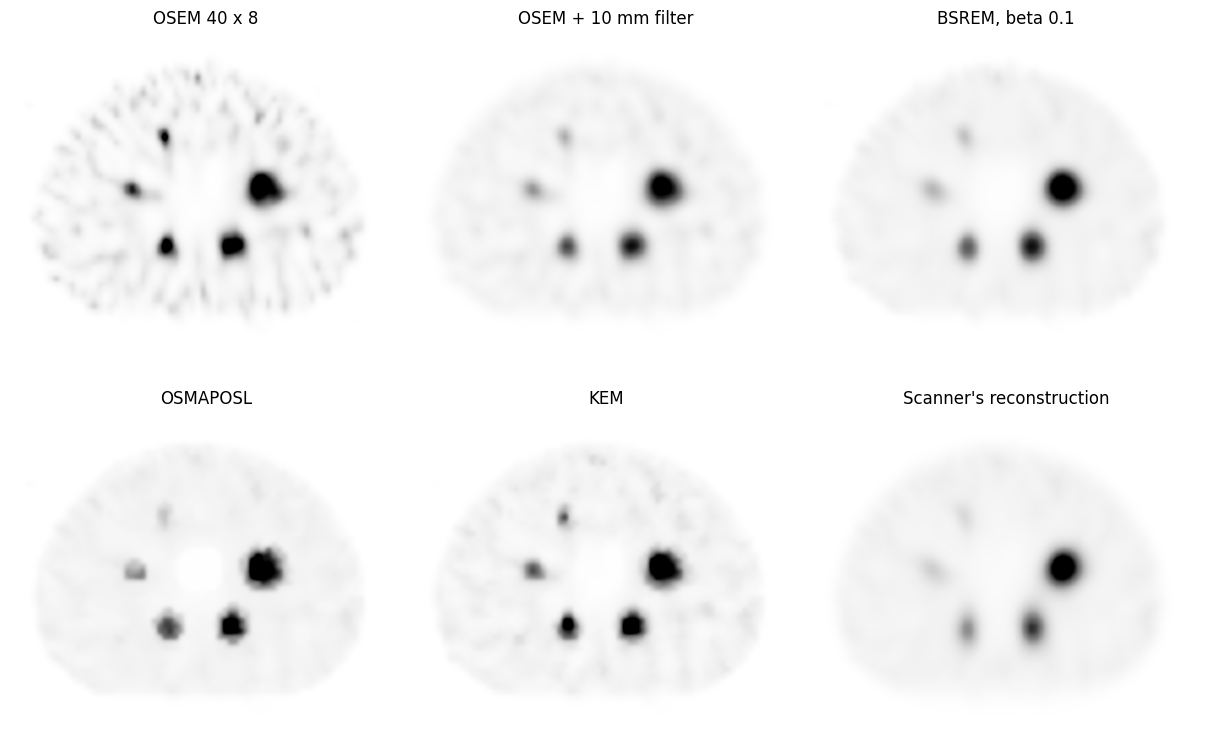

In [14]:
beta_shown = 0.1
images = [(f'OSEM {n_iters} x {n_subsets}', recon_osem), ('OSEM + 10 mm filter', recon_osem_filtered),
          (f'BSREM, beta {beta_shown}', recon_bsrem[beta_shown]), ('OSMAPOSL', recon_osmaposl), ('KEM', recon_kem),
          ("Scanner's reconstruction", recon_scanner)]
fig, axes = plt.subplots(2, 3, figsize=(12, 7.6), constrained_layout=True)
for ax, (name, image) in zip(axes.flat, images):
    ax.imshow((image[crop[0], crop[1], z] / image[background].mean()).cpu().T, cmap='Greys', vmin=0, vmax=10,
              interpolation='gaussian')  # anterior up
    ax.set_title(name)
    ax.axis('off')
plt.show()

After 40 iterations OSEM shows all five visible spheres, in a grainy background with streaks near the walls. The post-filter smooths everything, the edges of the spheres too. BSREM with `beta` 0.1, at about the scanner's noise, shows the spheres darker than the scanner's image does: the higher contrast of section 6. OSMAPOSL's weights come from the attenuation map, so the edge of the cold lung insert stays sharp. In the uniform water, though, the 8 neighbours most similar to a voxel are picked by the noise of the CT, so its smoothing has no consistent direction, and its spheres come out less round.

## Save the images

`io.save_dicom` writes each reconstruction as a DICOM nuclear medicine (NM) file, in counts, in its place in the patient (`object_meta.affine`). `reference=file_NM` gives them the patient and study of the projections, so DICOM viewers show them with the scan's CT.

In [15]:
for name, image in [('OSEM', recon_osem), ('OSEM_filtered', recon_osem_filtered), ('OSMAPOSL', recon_osmaposl),
                    ('BSREM', recon_bsrem[beta_shown]), ('KEM', recon_kem)]:
    io.save_dicom(image, OUTPUT / 't_algorithms_measured' / name, object_meta, reference=file_NM, units='counts',
                  series_description=f'{name.replace("_", " ")} {n_iters}x{n_subsets}', overwrite=True)

## Next steps

- Change `beta` and `gamma` of the priors, or the width of the post-filter, and see where their curves move.
- The [accuracy tutorial](t_accuracy_known_truth.ipynb) does the same measurements on a simulation, where the true concentrations are known, so it can give bias as well as noise.
- Use `PhantomStatistics` on your own phantom scans: it needs only a mask for each region.